<a href="https://colab.research.google.com/github/moiz-ezzi/Machine-Learning-Projects/blob/main/Car_Price_Model_Training_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
df=pd.read_csv('cleaned (1).csv')
df.head()

,Unnamed: 0,brand,model,year,price_pkr,mileage_km,fuel_type,transmission,engine_cc,city
0,0,Toyota,Prado,2003,6800000,161969.0,Petrol,0,3400.0,Lahore
1,1,Changan,Alsvin,2022,3050000,59216.0,Petrol,1,1300.0,Lahore
2,2,Suzuki,Cultus,2022,3400000,22120.0,Petrol,1,1000.0,Karachi
3,3,Honda,City,2025,6100000,14339.0,Petrol,0,1500.0,Rawalpindi
4,4,Hyundai,Santa,2026,14500000,10.0,Hybrid,0,1600.0,Karachi


In [ ]:
df.columns
df.drop('Unnamed: 0',axis=1,inplace=True)

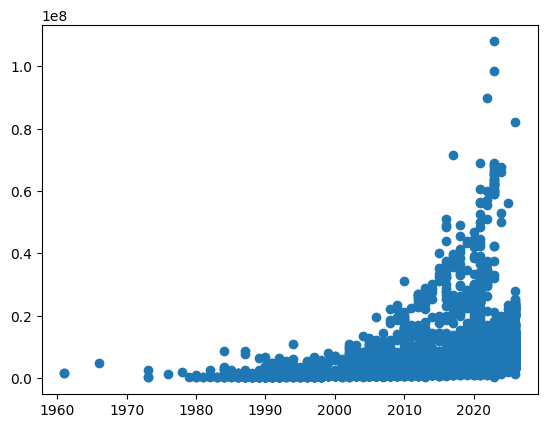

In [ ]:
plt.scatter(df['year'],df['price_pkr'])

<BarContainer object of 10486 artists>

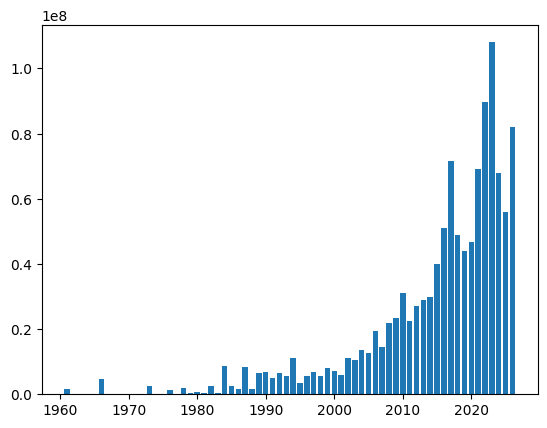

In [ ]:
plt.bar(df['year'],df['price_pkr'])

<Axes: xlabel='fuel_type', ylabel='count'>

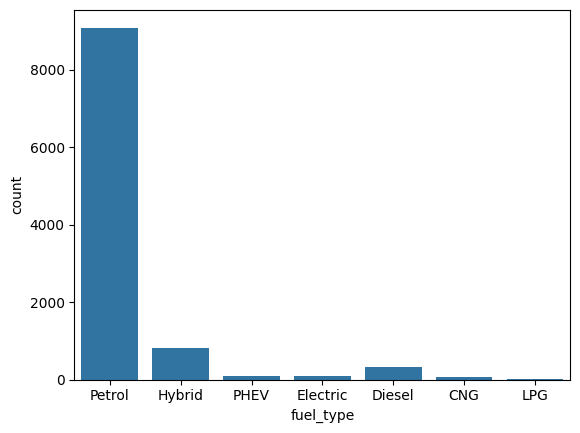

In [ ]:
sns.countplot(x=df['fuel_type'])

<Axes: xlabel='mileage_km', ylabel='price_pkr'>

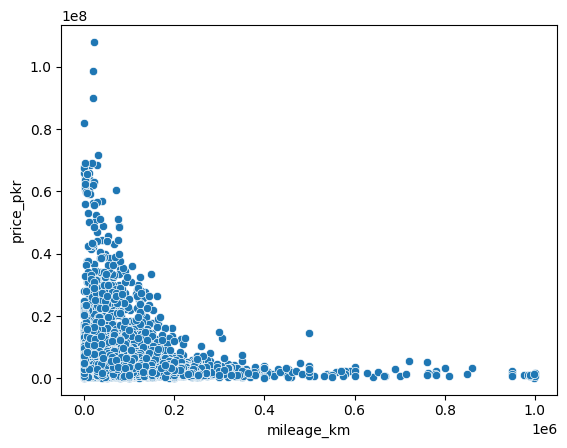

In [ ]:
sns.scatterplot(x='mileage_km',y='price_pkr',data=df)

<BarContainer object of 10486 artists>

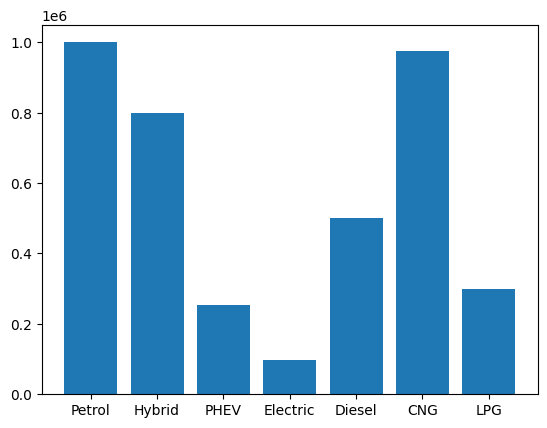

In [ ]:
plt.bar(df['fuel_type'],df['mileage_km'])

<Axes: xlabel='engine_cc', ylabel='price_pkr'>

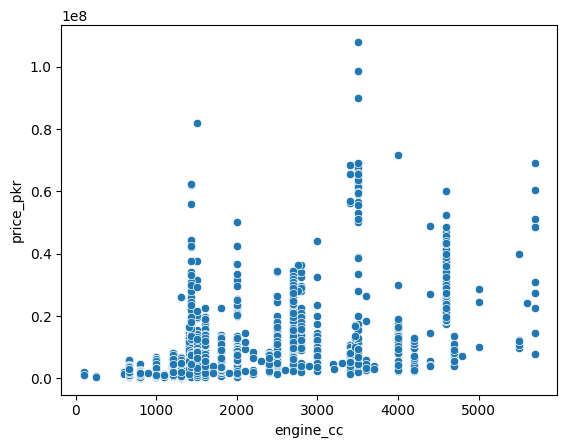

In [ ]:
sns.scatterplot(x=df['engine_cc'],y=df['price_pkr'])

{'whiskers': [<matplotlib.lines.Line2D at 0x7e8fac949590>,
 'caps': [<matplotlib.lines.Line2D at 0x7e8fac949810>,
 'boxes': [<matplotlib.lines.Line2D at 0x7e8fac949450>,
 'medians': [<matplotlib.lines.Line2D at 0x7e8fac949a90>,
 'fliers': [<matplotlib.lines.Line2D at 0x7e8fac949bd0>,
 'means': []}

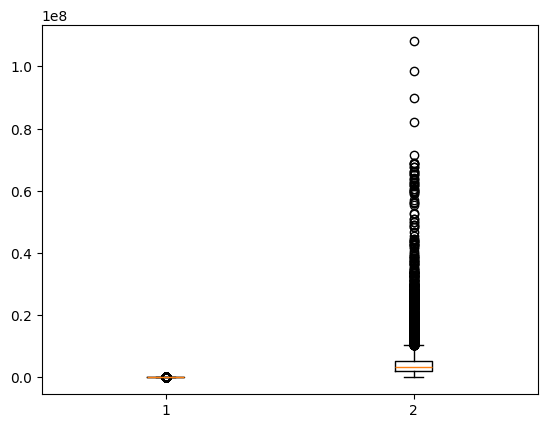

In [ ]:
all_data=df[['engine_cc','price_pkr']]
plt.boxplot(all_data)

In [ ]:
min,q1,median,q3,max=np.quantile(df['price_pkr'],[0,0.25,0.50,0.75,1.0])
q1,q3
iqr=q3-q1
lower_fence=q1-1.5*(iqr)
higher_fence=q3+1.5*(iqr)
lower_fence,higher_fence

(np.float64(-2725000.0), np.float64(10355000.0))

In [ ]:
df=df[(df['price_pkr']>=lower_fence) & (df['price_pkr']<=higher_fence)]

{'whiskers': [<matplotlib.lines.Line2D at 0x7e8fac7c56d0>,
 'caps': [<matplotlib.lines.Line2D at 0x7e8fac7c5950>,
 'boxes': [<matplotlib.lines.Line2D at 0x7e8fac7c5590>],
 'medians': [<matplotlib.lines.Line2D at 0x7e8fac7c5bd0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7e8fac7c5d10>],
 'means': []}

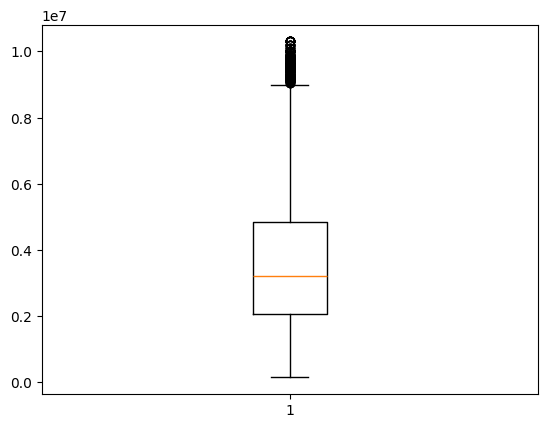

In [ ]:
plt.boxplot(df['price_pkr'])

In [ ]:
df=df.reset_index(drop=True)

In [ ]:
##Divinding the data
X=df.drop('price_pkr',axis=1)
y=df['price_pkr']
from sklearn.model_selection import train_test_split

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
X_train

,brand,model,year,mileage_km,fuel_type,transmission,engine_cc,city
7558,Toyota,Corolla,2014,98000.0,Petrol,1,1300.0,Gujar Khan
4999,Daihatsu,Cast,2021,42000.0,Petrol,0,660.0,Rawalpindi
1561,Honda,N,2022,68700.0,Petrol,0,660.0,Islamabad
8804,Toyota,Corolla,2016,115000.0,Petrol,0,1300.0,Lahore
6408,FAW,X-PV,2015,150000.0,Petrol,1,1000.0,Gujranwala
...,...,...,...,...,...,...,...,...
5734,Toyota,Corolla,2005,170000.0,Petrol,0,1500.0,Islamabad
5191,Toyota,Passo,2023,13000.0,Petrol,0,1000.0,Karachi
5390,Suzuki,Khyber,1996,150000.0,Petrol,1,1000.0,Karachi
860,Toyota,Raize,2021,44000.0,Petrol,0,1000.0,Peshawar


In [ ]:
##starting scaling the data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [ ]:
int_dtype=df.select_dtypes(exclude='object').columns.to_list()
int_dtype

['year', 'price_pkr', 'mileage_km', 'transmission', 'engine_cc']

In [ ]:
ct=ColumnTransformer(transformers=[('standard',StandardScaler(),['year', 'mileage_km', 'transmission', 'engine_cc']),
                                   ('onehot',OneHotEncoder(handle_unknown='ignore'),['brand','model','fuel_type','city'])],remainder='passthrough')

In [ ]:
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)

In [ ]:
print(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 62264 stored elements and shape (7783, 484)>
  Coords	Values
  (0, 0)	-0.059743337261719105
  (0, 1)	-0.061153851875970215
  (0, 2)	1.3152639759957265
  (0, 3)	-0.0511057619432602
  (0, 51)	1.0
  (0, 114)	1.0
  (0, 310)	1.0
  (0, 355)	1.0
  (1, 0)	0.789428788320163
  (1, 1)	-0.7567800369787038
  (1, 2)	-0.760303648735567
  (1, 3)	-1.266757782679189
  (1, 15)	1.0
  (1, 101)	1.0
  (1, 310)	1.0
  (1, 444)	1.0
  (2, 0)	0.9107390919747177
  (2, 1)	-0.42511540943865045
  (2, 2)	-0.760303648735567
  (2, 3)	-1.266757782679189
  (2, 20)	1.0
  (2, 202)	1.0
  (2, 310)	1.0
  (2, 368)	1.0
  (3, 0)	0.1828772700473901
  :	:
  (7779, 386)	1.0
  (7780, 0)	-2.2433288030437017
  (7780, 1)	0.584784748576568
  (7780, 2)	1.3152639759957265
  (7780, 3)	-0.6209426466632267
  (7780, 49)	1.0
  (7780, 174)	1.0
  (7780, 310)	1.0
  (7780, 386)	1.0
  (7781, 0)	0.789428788320163
  (7781, 1)	-0.7319362446536062
  (7781, 2)	-0.760303648735567
  (7781, 3)	-0

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
regressor=LinearRegression()
regressor.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred=regressor.predict(X_test)

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [ ]:
score=r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(score)
print(mae)
print(mse)

0.9012349521526472
478346.8867549011
490739912016.667


<Axes: xlabel='price_pkr'>

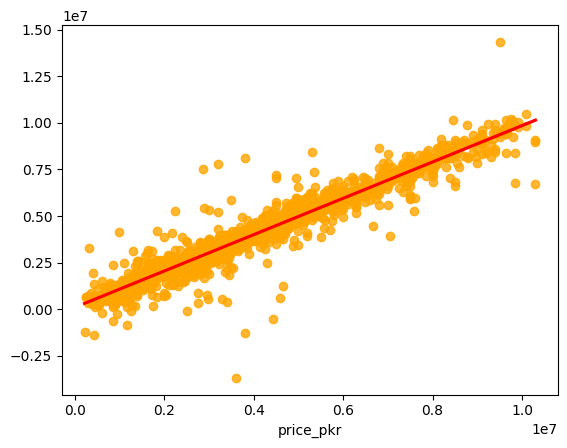

In [ ]:
sns.regplot(x=y_test,y=y_pred,line_kws={'color':'red'},scatter_kws={'color':'orange'})